## Generating various maps and plots to demonstrate the change in Pontal do Paranapanema's NDVI values overtime 

In [1]:
### restore variables
%store -r pontal_ndvi_da pontal_gdf

In [2]:
### import libraries (all libraries for this project)

### set data and export path
import os

### working with dataframes
import pandas as pd

### build and work with geodataframes
import geopandas as gpd
from shapely.geometry import Polygon

### making interactive plots of gdf's and df's
import hvplot.pandas 

### interactive plots with rasters 
import hvplot.xarray

### work with pattern matching rules for file names
from glob import glob

### handle geospatial rasters
import rioxarray as rxr

### work with arrays
import xarray as xr

### display interactive plot in notebook w/ slider
import panel as pn
pn.extension(comms = 'vscode')
import holoviews as hv
hv.extension('bokeh')

### fit a trend line to plot and get slope
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.linear_model import LinearRegression

### access the MODIS data 
import earthpy
import earthpy.api.appeears as eaapp


print("Libraries imported successfully")

Libraries imported successfully


In [3]:
### solution to coordinate system key error lon_0
import cartopy.crs as ccrs

### save cartopy original version once
if not hasattr(ccrs.PlateCarree, '_original_proj4_params'):
    ccrs.PlateCarree._original_proj4_params = ccrs.PlateCarree.proj4_params

def _proj4_params_with_lon_0(self):
    params = ccrs.PlateCarree._original_proj4_params.fget(self)
    params.setdefault('lon_0', params.get('pm', 0))
    return params

ccrs.PlateCarree.proj4_params = property(_proj4_params_with_lon_0)

In [4]:
### solution to extensive list of warnings not affecting code
import warnings
warnings.filterwarnings(
    "ignore",
    message=".*invalid value encountered in create_collection.*",
    category=RuntimeWarning
)

In [5]:
### Solution to plots not displaying
%pip install -U jupyter_bokeh

Note: you may need to restart the kernel to use updated packages.


### Creating a slider map of annual median NDVI values from 2000-2026

In [6]:
### calcualte one NDVI image per year during dry season
pontal_ndvi_annual_da = (
    pontal_ndvi_da

    ### group by year
    .groupby(pontal_ndvi_da.date.dt.year)

    ### take the median of each (to prevent clouds/smoke obscuring mean)
    .median('date')
    .NDVI 
)

### check for 27 values 
pontal_ndvi_annual_da

<xarray.DataArray 'NDVI' (year: 27, y: 622, x: 1101)> Size: 74MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]],
      shape=(27, 622, 1101), dtype=float32)
Coordinates:
  * year         (year) int64 216B 2000 2001 2002 2003 ... 2023 2024 2025 2026
  * y            (y) float64 5kB -21.43 -21.43 -21.43 ... -22.72 -22.72 -22.72
  * x            (x) float64 9kB -53.23 -53.23 -53.23 ... -50.94 -50.94 -50.94
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    units:          NDVI
    AREA_OR_POINT:  Area

In [7]:
### I think nan values are coming 
### from the parts of raster that fall outside my polygon,
### check here
pontal_ndvi_annual_da.count(['x', 'y']).to_series()

year
2000    446875
2001    435692
2002    431594
2003    425588
2004    429213
2005    439813
2006    434625
2007    436947
2008    440303
2009    441306
2010    434100
2011    437123
2012    438415
2013    426778
2014    427620
2015    444373
2016    433282
2017    441379
2018    447687
2019    450209
2020    456219
2021    447565
2022    453887
2023    449877
2024    452200
2025    443172
2026    454837
Name: NDVI, dtype: int64

Values above make sense, good to precede

In [12]:
### trim down data bounds so slider can generate easier (AI recommednation)
#pontal_ndvi_slider_da = pontal_ndvi_annual_da.coarsen(
    #x = 2, y = 2, boundary = 'trim').mean()

### create slider plot

### get plot bounds so they don't change with slider
xmin, ymin, xmax, ymax = pontal_gdf.total_bounds

### define the slider widget
slider = pn.widgets.DiscreteSlider(
    name = 'year',
    options = [int(year) for year in
    pontal_ndvi_annual_da.year.values]
)
### plot NDVI by year
pontal_ndvi_slider_map = (
    pontal_ndvi_annual_da
    .hvplot(
        x = 'x', y = 'y',

        ### color by NDVI
        cmap = 'Greens', clim = (0.2, 0.9),

        ### group by year
        groupby = 'year',

        ### set basemap
        geo = True, tiles = 'EsriImagery',

        ### add a title 
        title = "Annual NDVI Overtime in Pontal" \
        " do Paranapanema, São Paulo, Brazil",

        ### set plot boundaries
        xlim = (xmin, xmax), ylim = (ymin, ymax),

        ### set dimensions
        frame_height = 600,
        frame_width = 900,

        ### display NDVI scale
        colorbar = True
    )
    ### add pontal boundary
    * pontal_gdf.hvplot(
    geo = True, fill_color = None, line_color = 'white')
)

### wrap plot in the panel layout
pontal_ndvi_slider_map = pn.panel(
    pontal_ndvi_slider_map,

    ### set slider to bottom of map
    widget_location = 'bottom',
    widgets = {'year': slider}
)

### check it out
display(pontal_ndvi_slider_map)

BokehModel(combine_events=True, render_bundle={'docs_json': {'25856f6a-0311-4e6b-85f2-cf25ec148735': {'version…

In [9]:
### create folder for exported plots
plot_dir = 'pontal_ndvi_plots'
os.makedirs(plot_dir, exist_ok = True)

### make path for the map
pontal_ndvi_slider_map_path = os.path.join(
    plot_dir, "pontal_ndvi_slider_map_full.html")

### only export map once
if not os.path.exists(pontal_ndvi_slider_map_path):

    ### export map as html file
    pontal_ndvi_slider_map.save(
    pontal_ndvi_slider_map_path,
    embed = True,
    resources = 'inline'
)

print(os.path.abspath(pontal_ndvi_slider_map_path))

/Users/haydensimmons/Documents/earth_analytics_bootcamp/earth-analytics-final-project/pontal_ndvi_plots/pontal_ndvi_slider_map_full.html


### Creating a trend line plot of the Mean NDVI per year from 2000-2026, marking when resotration began

In [10]:
### calculate mean dry season NDVI values across the time series
pontal_mean_ndvi_df = (
    pontal_ndvi_annual_da

    ### group by year
    .groupby('year')

    ### claculate each years mean
    .mean(...)

    ### extract NDVI and add to dataframe
    .to_dataframe()

    ### keep only NDVI values
    [['NDVI']]
)

pontal_mean_ndvi_df

,NDVI
year,
2000,0.475327
2001,0.509433
2002,0.516860
2003,0.492116
2004,0.490371
2005,0.495303
2006,0.466862
2007,0.458833
2008,0.490885


In [11]:
### plot mean NDVI over time
pontal_ndvi_line_plot = (
    pontal_mean_ndvi_df.hvplot(
        title = "Mean Dry Season NDVI from 2000-2026," \
        "Pontal do Paranapanema, São Paulo, Brazil",
        xlabel = "Year", ylabel = "Mean NDVI Values",
        legend = True
    )
    ### mark when IPE resotartion began
    * hv.VLine(2002).opts(color = 'orange', line_dash = 'dashed')
)

display(pontal_ndvi_line_plot)

:Overlay
   .Curve.I :Curve   [year]   (NDVI)
   .VLine.I :VLine   [x,y]

In [16]:
### make path for the map
pontal_ndvi_line_plot_path = os.path.join(
    plot_dir, "pontal_mean_ndvi_line_plot.html")

### only export map once
if not os.path.exists(pontal_ndvi_line_plot_path):

    ### export map as html file
    hvplot.save(
        pontal_ndvi_line_plot,
        pontal_ndvi_line_plot_path,
        resources = 'inline'
)

print(os.path.abspath(pontal_ndvi_line_plot_path))

/Users/haydensimmons/Documents/earth_analytics_bootcamp/earth-analytics-final-project/pontal_ndvi_plots/pontal_mean_ndvi_line_plot.html


### Fit an OLS linear regression trend line to the NDVI trend since restoration efforts began (2002)

In [19]:
### subset data to focus on 2002 and on
restoration_progress_df = pontal_mean_ndvi_df.loc[2002:].dropna()

### fit an OLS Linear Regression

### define independant variable
### reshape 'year' to be a 2D array for scikit-learn
ind_variable = restoration_progress_df.index.values.reshape(-1, 1)

### define dependent variable
dep_variable = restoration_progress_df

### make linear regression model
model = LinearRegression()

### fit the model on the data
model.fit(ind_variable, dep_variable)

### calculate and print metrics
print(f'Slope: {model.coef_[0]} NDVI per year')



Slope: [9.82860877e-05] NDVI per year


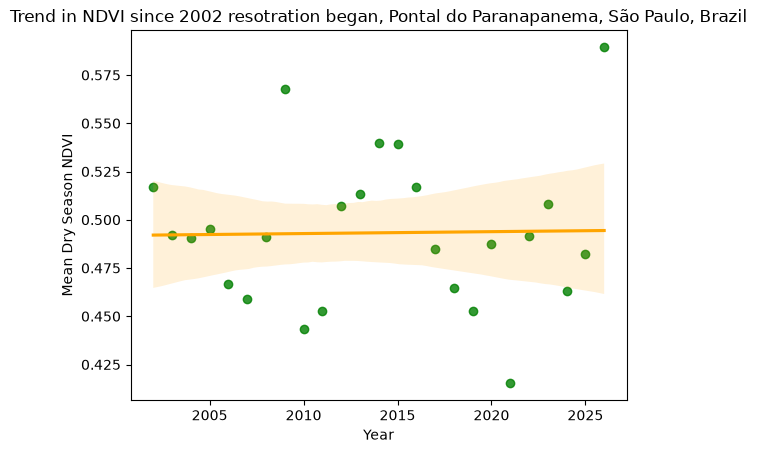

In [22]:
### plot the data with a trend line
ax = sns.regplot(
    x = restoration_progress_df.index,
    y = restoration_progress_df['NDVI'],

    ### change color of data points
    color = 'green',

    ### change color of trend line
    line_kws = {'color' : 'orange'}
)

### set labels
ax.set(
    title = "Trend in NDVI since 2002 resotration began, Pontal do Paranapanema, São Paulo, Brazil",
    xlabel = "Year",
    ylabel = "Mean Dry Season NDVI",
)

### save plot
plt.savefig(os.path.join(plot_dir, 'pontal_ndvi_trend.jpeg'))

### show plot
plt.show()

### Creating a difference map of NDVI values from when restoration began to modern day

In [23]:
#### calculate before restoation NDVI
pontal_ndvi_pre = (

    ### get annual NDVI data
    pontal_ndvi_annual_da

    ### focus on pre-restoration
    .sel( year = slice (2000, 2001))

    ### calcualte mean pre
    .mean('year')
)

### calculate recent NDVI
pontal_ndvi_post = (

    ### get annual NDVI data
    pontal_ndvi_annual_da

    ### select recent years
    .sel(year = slice(2025, 2026))

    ### clalculate mean post
    .mean('year')
)

In [24]:
### calculate change between pre and post
pontal_ndvi_diff = pontal_ndvi_post - pontal_ndvi_pre

### plot the difference
pontal_ndvi_diff_map = (
    pontal_ndvi_diff.hvplot(
        x = 'x', 
        y = 'y',
        geo = True,
        tiles = 'EsriImagery',
        cmap = 'PiYG',
        clim = (-0.3, 0.3),
        frame_width = 900,
        title = "Change in NDVI values before (2000-2001) and after (2025-2026)" \
        " restoartion efforts, Pontal do Paranapanema, São Paulo, Brazil"
    )

    ### add pontal polygon
    * pontal_gdf.hvplot(geo = True, fill_color = None, line_color = 'white')
)

display(pontal_ndvi_diff_map)

:Overlay
   .WMTS.I     :WMTS   [Longitude,Latitude]
   .Image.I    :Image   [x,y]   (NDVI)
   .Polygons.I :Polygons   [Longitude,Latitude]

In [26]:
### make a apth for the map
pontal_ndvi_diff_map_path = os.path.join(
    plot_dir, "pontal_ndvi_difference_map.html")

### export once
if not os.path.exists(pontal_ndvi_diff_map_path):

    ### export map as html file
    hvplot.save(
        pontal_ndvi_diff_map,
        pontal_ndvi_diff_map_path,
        resources = 'inline'
    )

print(os.path.abspath(pontal_ndvi_diff_map_path))

/Users/haydensimmons/Documents/earth_analytics_bootcamp/earth-analytics-final-project/pontal_ndvi_plots/pontal_ndvi_difference_map.html
